# 04 · Object detection: R-CNN, YOLO, SSD

**Covers (Week 3 Key Concepts, "Object Detection Architectures"):** R-CNN (2014), YOLO (2016), SSD (2016) and the **accuracy vs speed** trade-off.
**Questions answered here:** Easy 15–18 · Medium 10–14 · Hard 5–6.

> **Object detection = identifying *what* each object is AND *where* it is**: a **class label + a bounding box** for every object in the image.

| Task | Output | Example |
|---|---|---|
| Classification | one label for the whole image | "cat" |
| Localization | one label + one box | "cat, at (40, 30, 120, 110)" |
| **Detection** | **a label + box for EVERY object** | "cat here, dog there, person there" |
| Segmentation (notebook 05) | a label for every **pixel** | exact outline of each object |

In this notebook we **build tiny versions of R-CNN and YOLO ourselves** on a synthetic "shapes" dataset and race them. Both train on a laptop CPU in about 2 minutes.

In [1]:
%matplotlib inline
import time
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
import cv2
import torch
import torch.nn as nn
import torch.nn.functional as F
from torchvision.ops import nms, box_iou, roi_align

torch.manual_seed(0)
print("torch", torch.__version__)

torch 2.14.1+cu130


## 1 · Two tools every detector uses: IoU and NMS

### IoU (Intersection over Union): "how much do two boxes overlap?"

  **IoU = area of overlap / area of union**: 1 = identical boxes, 0 = no overlap.

It's used to (a) decide whether a predicted box **counts as correct** (usually IoU ≥ 0.5 with the true box) and (b) remove duplicate boxes (NMS, below). Boxes are written as **(x1, y1, x2, y2)**: top-left and bottom-right corners.

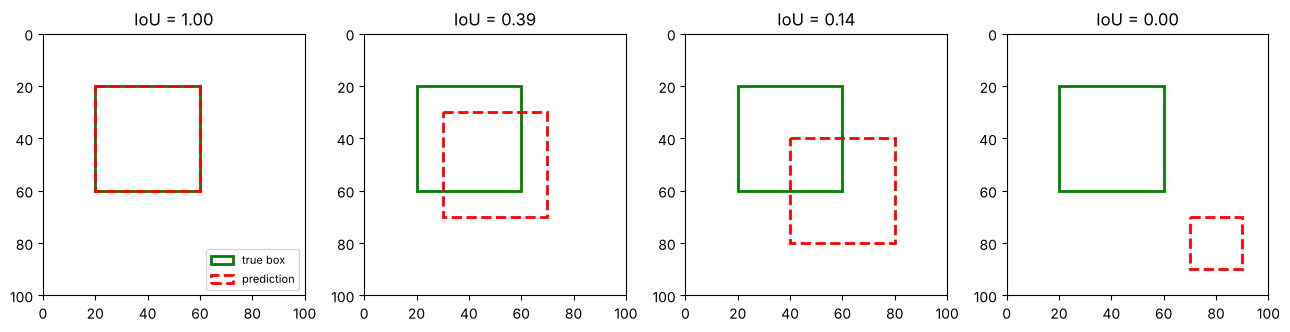

check with torchvision: [[1.   0.39 0.14 0.  ]]


In [2]:
def iou(a, b):
    x1, y1 = max(a[0], b[0]), max(a[1], b[1])          # overlap rectangle: the inner corners
    x2, y2 = min(a[2], b[2]), min(a[3], b[3])
    inter = max(0, x2 - x1) * max(0, y2 - y1)
    area_a = (a[2] - a[0]) * (a[3] - a[1])
    area_b = (b[2] - b[0]) * (b[3] - b[1])
    return inter / (area_a + area_b - inter)            # union = A + B - overlap (don't count it twice)

truth = (20, 20, 60, 60)
examples = [(20, 20, 60, 60), (30, 30, 70, 70), (40, 40, 80, 80), (70, 70, 90, 90)]
fig, ax = plt.subplots(1, 4, figsize=(13, 3.3))
for a, pred in zip(ax, examples):
    a.add_patch(mpatches.Rectangle(truth[:2], 40, 40, fill=False, ec="green", lw=2, label="true box"))
    a.add_patch(mpatches.Rectangle(pred[:2], pred[2] - pred[0], pred[3] - pred[1], fill=False, ec="red", lw=2, ls="--", label="prediction"))
    a.set_xlim(0, 100); a.set_ylim(100, 0); a.set_aspect("equal")
    a.set_title(f"IoU = {iou(truth, pred):.2f}")
ax[0].legend(loc="lower right", fontsize=8)
plt.tight_layout(); plt.show()
print("check with torchvision:", box_iou(torch.tensor([truth], dtype=torch.float32), torch.tensor(examples, dtype=torch.float32)).numpy().round(2))

### NMS (Non-Maximum Suppression): "keep the best box, delete its duplicates"

Detectors usually fire **several overlapping boxes on the same object**. NMS cleans this up:
1. Sort boxes by confidence score.
2. Keep the highest-scoring box and **delete every other box that overlaps it** with IoU > threshold (e.g. 0.5).
3. Repeat with the next remaining box.

kept boxes (mine)       : [np.int64(0), np.int64(3)]
kept boxes (torchvision): [0, 3]


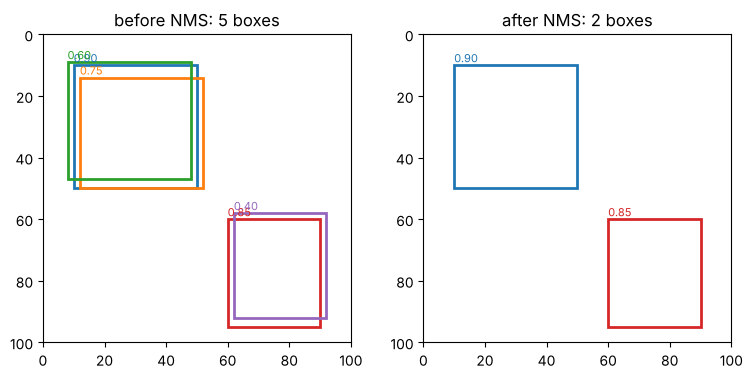

In [3]:
def my_nms(boxes, scores, thresh=0.5):
    order = list(np.argsort(scores)[::-1])           # best first
    keep = []
    while order:
        best = order.pop(0)
        keep.append(best)
        order = [i for i in order if iou(boxes[best], boxes[i]) <= thresh]   # drop the duplicates of `best`
    return keep

boxes = [(10, 10, 50, 50), (12, 14, 52, 50), (8, 9, 48, 47), (60, 60, 90, 95), (62, 58, 92, 92)]
scores = [0.90, 0.75, 0.60, 0.85, 0.40]
kept = my_nms(boxes, scores)
print("kept boxes (mine)       :", sorted(kept))
print("kept boxes (torchvision):", sorted(nms(torch.tensor(boxes, dtype=torch.float32), torch.tensor(scores), 0.5).tolist()))

fig, ax = plt.subplots(1, 2, figsize=(9, 4))
for a, idxs, title in [(ax[0], range(len(boxes)), "before NMS: 5 boxes"), (ax[1], kept, f"after NMS: {len(kept)} boxes")]:
    for i in idxs:
        b = boxes[i]
        a.add_patch(mpatches.Rectangle(b[:2], b[2] - b[0], b[3] - b[1], fill=False, ec="C%d" % i, lw=2))
        a.text(b[0], b[1] - 1, f"{scores[i]:.2f}", color="C%d" % i, fontsize=8)
    a.set_xlim(0, 100); a.set_ylim(100, 0); a.set_aspect("equal"); a.set_title(title)
plt.show()

## 2 · A dataset we can train on in minutes

Real detectors train on COCO (118,000 photos, 80 classes) for days on GPUs. We make our own: **96×96 scenes with 1–3 objects** (circle, square or triangle) of different sizes on a noisy background. We know the exact boxes because we drew them.

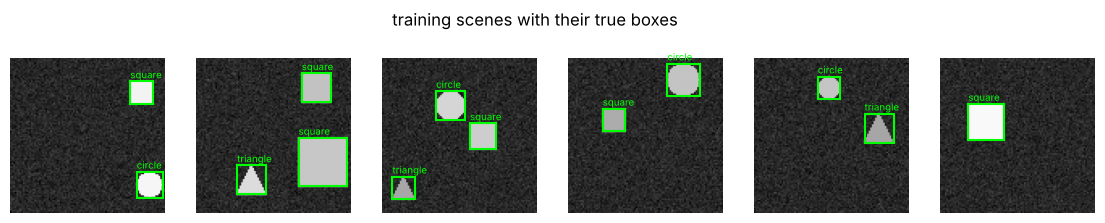

In [4]:
CLASSES = ["circle", "square", "triangle"]
IMG = 96

def draw_shape(img, cls, cx, cy, r, brightness):
    if cls == 0:
        cv2.circle(img, (cx, cy), r, brightness, -1)
    elif cls == 1:
        cv2.rectangle(img, (cx - r, cy - r), (cx + r, cy + r), brightness, -1)
    else:
        cv2.fillPoly(img, [np.array([[cx, cy - r], [cx - r, cy + r], [cx + r, cy + r]], np.int32)], brightness)

def make_scene(rng, max_objects=3):
    img = rng.normal(40, 12, (IMG, IMG)).clip(0, 255).astype(np.uint8)       # noisy dark background
    boxes, labels = [], []
    for _ in range(rng.integers(1, max_objects + 1)):
        for _attempt in range(20):                                           # find a spot that doesn't overlap
            r = int(rng.integers(6, 16)); cx = int(rng.integers(r + 1, IMG - r - 1)); cy = int(rng.integers(r + 1, IMG - r - 1))
            box = [cx - r, cy - r, cx + r, cy + r]
            if all(iou(box, b) == 0 for b in boxes):
                cls = int(rng.integers(0, 3))
                draw_shape(img, cls, cx, cy, r, int(rng.integers(150, 255)))
                boxes.append(box); labels.append(cls)
                break
    return img, np.array(boxes, np.float32), np.array(labels)

rng = np.random.default_rng(0)
train_scenes = [make_scene(rng) for _ in range(3000)]
test_scenes = [make_scene(rng) for _ in range(200)]

def show_scene(ax, img, boxes, labels, scores=None, color="lime"):
    ax.imshow(img, cmap="gray", vmin=0, vmax=255); ax.axis("off")
    for k, ((x1, y1, x2, y2), c) in enumerate(zip(boxes, labels)):
        ax.add_patch(mpatches.Rectangle((x1, y1), x2 - x1, y2 - y1, fill=False, ec=color, lw=1.5))
        txt = CLASSES[int(c)] + (f" {scores[k]:.2f}" if scores is not None else "")
        ax.text(x1, y1 - 2, txt, color=color, fontsize=7)

fig, ax = plt.subplots(1, 6, figsize=(14, 2.6))
for a, (img, b, l) in zip(ax, train_scenes[:6]):
    show_scene(a, img, b, l)
plt.suptitle("training scenes with their true boxes"); plt.show()

In [5]:
def evaluate(all_predictions, scenes=test_scenes):
    # A prediction is correct if IoU >= 0.5 with a true box of the SAME class (each true box used once)
    tp = fp = fn = 0
    for preds, (img, boxes, labels) in zip(all_predictions, scenes):
        gt = torch.tensor(boxes); used = set()
        for box, score, cls in preds:
            ious = box_iou(torch.tensor([box], dtype=torch.float32), gt)[0]
            k = int(ious.argmax())
            if ious[k] >= 0.5 and k not in used and labels[k] == cls:
                tp += 1; used.add(k)
            else:
                fp += 1
        fn += len(boxes) - len(used)
    precision = tp / max(tp + fp, 1)      # of the boxes we drew, how many were right?
    recall = tp / max(tp + fn, 1)         # of the real objects, how many did we find?
    return precision, recall

## 3 · R-CNN (2014): "propose regions, then classify each one"

**Full name:** Region-based Convolutional Neural Network (Girshick et al.).
**Process:**
1. **Generate region proposals**: about 2,000 "maybe there's an object here" boxes per image (R-CNN used the *selective search* algorithm).
2. **Run a CNN on each region** separately: crop, resize, classify.
3. **Classify and refine** the bounding boxes, then remove duplicates with NMS.

**Strength:** high accuracy. **Weakness:** very slow, because the CNN runs **thousands of times per image**.
**Key contribution:** the first major CNN-based detector. It proved deep learning works for detection.

Our version: proposals = **sliding windows** of 6 sizes (simpler than selective search), and the CNN is a small classifier for 4 classes: *background, circle, square, triangle*.

In [6]:
def make_proposals():
    out = []
    for size in [12, 16, 20, 24, 28, 32]:                 # windows of several sizes...
        for y in range(0, IMG - size + 1, 4):             # ...slid across the image every 4 pixels
            for x in range(0, IMG - size + 1, 4):
                out.append([x, y, x + size, y + size])
    return torch.tensor(out, dtype=torch.float32)

PROPOSALS = make_proposals()
print("region proposals per image:", len(PROPOSALS))

CROP = 24
def crop_regions(img, boxes):
    # cut out every box and resize it to 24x24 (roi_align does crop+resize for many boxes at once)
    t = torch.tensor(img, dtype=torch.float32)[None, None] / 255
    return roi_align(t, [boxes], output_size=(CROP, CROP), aligned=True)

# Training crops: true boxes (slightly jittered) = object classes 1..3;
# background = random windows (IoU < 0.3) + "hard negatives" that cover only PART of an object (IoU 0.1-0.45)
rng2 = np.random.default_rng(1)
crops, crop_labels = [], []
for img, boxes, labels in train_scenes[:1500]:
    gt = torch.tensor(boxes)
    jittered = gt + torch.tensor(rng2.integers(-2, 3, gt.shape), dtype=torch.float32)
    crops.append(crop_regions(img, jittered)); crop_labels += [int(l) + 1 for l in labels]
    best_iou = box_iou(PROPOSALS, gt).max(1).values
    background = PROPOSALS[best_iou < 0.3][torch.tensor(rng2.choice(int((best_iou < 0.3).sum()), 3, replace=False))]
    partial = PROPOSALS[(best_iou > 0.1) & (best_iou < 0.45)]
    if len(partial) >= 3:
        background = torch.cat([background, partial[torch.tensor(rng2.choice(len(partial), 3, replace=False))]])
    crops.append(crop_regions(img, background)); crop_labels += [0] * len(background)
crops = torch.cat(crops); crop_labels = torch.tensor(crop_labels)
print("training crops:", tuple(crops.shape), " class counts (bg, circle, square, triangle):", torch.bincount(crop_labels).tolist())

torch.manual_seed(0)
region_classifier = nn.Sequential(
    nn.Conv2d(1, 16, 3, padding=1), nn.ReLU(), nn.MaxPool2d(2),
    nn.Conv2d(16, 32, 3, padding=1), nn.ReLU(), nn.MaxPool2d(2),
    nn.Flatten(), nn.Linear(32 * 6 * 6, 64), nn.ReLU(), nn.Linear(64, 4))
opt = torch.optim.Adam(region_classifier.parameters(), lr=2e-3)
t = time.time()
for epoch in range(8):
    perm = torch.randperm(len(crops))
    for i in range(0, len(crops), 128):
        idx = perm[i:i + 128]
        loss = F.cross_entropy(region_classifier(crops[idx]), crop_labels[idx])
        opt.zero_grad(); loss.backward(); opt.step()
region_classifier.eval()
print(f"region classifier trained in {time.time() - t:.0f} s")

region proposals per image: 2299


training crops: (11993, 1, 24, 24)  class counts (bg, circle, square, triangle): [9000, 1015, 985, 993]


region classifier trained in 9 s


In [7]:
def rcnn_detect(img, score_threshold=0.9):
    with torch.no_grad():
        probs = F.softmax(region_classifier(crop_regions(img, PROPOSALS)), dim=1)   # CNN on EVERY proposal
    score, cls = probs[:, 1:].max(1)                    # best non-background class per proposal
    keep = score > score_threshold
    boxes, score, cls = PROPOSALS[keep], score[keep], cls[keep]
    final = nms(boxes, score, 0.3)                      # remove duplicates
    return [(boxes[i].tolist(), score[i].item(), cls[i].item()) for i in final]

t = time.time()
rcnn_preds = [rcnn_detect(img) for img, _, _ in test_scenes]
rcnn_ms = (time.time() - t) / len(test_scenes) * 1000
rcnn_p, rcnn_r = evaluate(rcnn_preds)
print(f"R-CNN style: precision {rcnn_p:.1%}, recall {rcnn_r:.1%}, {rcnn_ms:.0f} ms per image "
      f"({len(PROPOSALS)} CNN runs per image)")

R-CNN style: precision 72.2%, recall 91.9%, 196 ms per image (2299 CNN runs per image)


## 4 · YOLO (2016): "You Only Look Once"

**Process:** treat detection as **one regression problem**. Split the image into an **S×S grid** (we use 6×6, so each cell is 16×16 pixels). In **one forward pass**, every cell predicts:
- **objectness**: "is the centre of an object in me?" (0–1),
- **box**: x and y offset inside the cell, width, height,
- **class probabilities**: circle / square / triangle.

So the network's output is a 6 × 6 × (1 + 4 + 3) block of numbers, the whole answer at once.

**Strength:** **real-time** speed. **Weakness:** less accurate for **small objects**, especially small objects close together, because each cell predicts only a limited number of objects.
**Key contribution:** made detection practical for real-time uses like self-driving cars.

In [8]:
S = 6
CELL = IMG // S

def encode_target(boxes, labels):
    # turn the true boxes into the 6x6x8 grid of numbers the network should output
    t = torch.zeros(S, S, 5 + len(CLASSES))
    for (x1, y1, x2, y2), c in zip(boxes.tolist(), labels):
        cx, cy, w, h = (x1 + x2) / 2, (y1 + y2) / 2, x2 - x1, y2 - y1
        i, j = int(cy // CELL), int(cx // CELL)          # the cell that contains the object's CENTRE
        t[i, j, 0] = 1                                   # objectness
        t[i, j, 1:5] = torch.tensor([cx / CELL - j, cy / CELL - i, w / IMG, h / IMG])
        t[i, j, 5 + c] = 1                               # one-hot class
    return t

Xtr = torch.tensor(np.stack([s[0] for s in train_scenes]), dtype=torch.float32)[:, None] / 255
Ytr = torch.stack([encode_target(s[1], s[2]) for s in train_scenes])
Xte = torch.tensor(np.stack([s[0] for s in test_scenes]), dtype=torch.float32)[:, None] / 255

class TinyYOLO(nn.Module):
    def __init__(self):
        super().__init__()
        def block(i, o):
            return nn.Sequential(nn.Conv2d(i, o, 3, padding=1), nn.BatchNorm2d(o), nn.LeakyReLU(0.1))
        self.net = nn.Sequential(
            block(1, 16), nn.MaxPool2d(2),       # 96 -> 48
            block(16, 32), nn.MaxPool2d(2),      # 48 -> 24
            block(32, 64), nn.MaxPool2d(2),      # 24 -> 12
            block(64, 64), nn.MaxPool2d(2),      # 12 -> 6   (one value per grid cell)
            block(64, 128), nn.Conv2d(128, 5 + len(CLASSES), 1))
    def forward(self, x):
        return self.net(x).permute(0, 2, 3, 1)  # (batch, 6, 6, 8)

def yolo_loss(pred, target):
    has_obj = target[..., 0] == 1
    objectness = F.binary_cross_entropy_with_logits(pred[..., 0], target[..., 0])      # every cell
    box = F.mse_loss(torch.sigmoid(pred[..., 1:5][has_obj]), target[..., 1:5][has_obj])  # only cells with objects
    cls = F.cross_entropy(pred[..., 5:][has_obj], target[..., 5:][has_obj].argmax(-1))
    return 5 * objectness + 5 * box + cls

torch.manual_seed(0)
yolo = TinyYOLO()
opt = torch.optim.Adam(yolo.parameters(), lr=2e-3)
t = time.time()
for epoch in range(12):
    yolo.train()
    perm = torch.randperm(len(Xtr))
    for i in range(0, len(Xtr), 64):
        idx = perm[i:i + 64]
        loss = yolo_loss(yolo(Xtr[idx]), Ytr[idx])
        opt.zero_grad(); loss.backward(); opt.step()
yolo.eval()
print(f"TinyYOLO trained in {time.time() - t:.0f} s")

TinyYOLO trained in 83 s


               precision   recall  ms / image
R-CNN style        72.2%    91.9%       195.9
YOLO style         99.5%    99.0%         1.6

YOLO is about 126x faster: 1 network run per image instead of 2299.


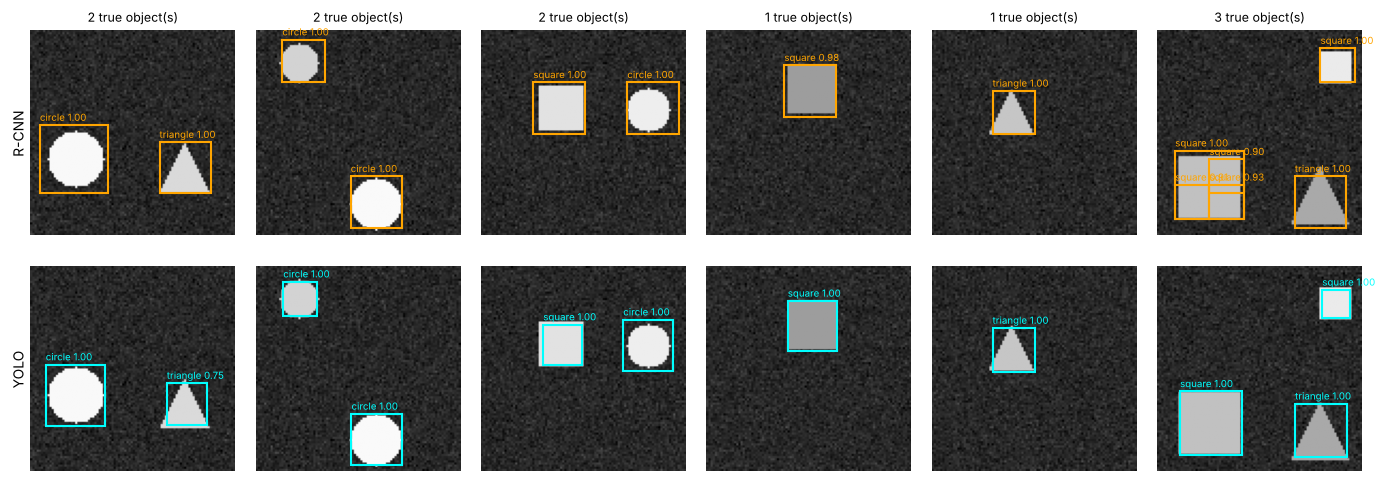

In [9]:
def yolo_decode(pred, threshold=0.5):
    conf = torch.sigmoid(pred[..., 0])
    out = []
    for i in range(S):
        for j in range(S):
            if conf[i, j] > threshold:
                ox, oy, w, h = torch.sigmoid(pred[i, j, 1:5]).tolist()
                cx, cy, w, h = (j + ox) * CELL, (i + oy) * CELL, w * IMG, h * IMG
                out.append(([cx - w / 2, cy - h / 2, cx + w / 2, cy + h / 2], conf[i, j].item(), pred[i, j, 5:].argmax().item()))
    return out

t = time.time()
with torch.no_grad():
    raw = yolo(Xte)                                         # ONE forward pass for all 200 images
yolo_ms = (time.time() - t) / len(Xte) * 1000
yolo_preds = [yolo_decode(raw[k]) for k in range(len(Xte))]
yolo_p, yolo_r = evaluate(yolo_preds)

print(f"{'':<14}{'precision':>10}{'recall':>9}{'ms / image':>12}")
print(f"{'R-CNN style':<14}{rcnn_p:>10.1%}{rcnn_r:>9.1%}{rcnn_ms:>12.1f}")
print(f"{'YOLO style':<14}{yolo_p:>10.1%}{yolo_r:>9.1%}{yolo_ms:>12.1f}")
print(f"\nYOLO is about {rcnn_ms / yolo_ms:.0f}x faster: 1 network run per image instead of {len(PROPOSALS)}.")

fig, ax = plt.subplots(2, 6, figsize=(14, 5.2))
for k in range(6):
    img, b, l = test_scenes[k]
    for row, preds, name in [(0, rcnn_preds[k], "R-CNN style"), (1, yolo_preds[k], "YOLO style")]:
        show_scene(ax[row, k], img, [p[0] for p in preds], [p[2] for p in preds], [p[1] for p in preds],
                   color="orange" if row == 0 else "cyan")
    ax[0, k].set_title(f"{len(b)} true object(s)", fontsize=9)
ax[0, 0].text(-10, 48, "R-CNN", rotation=90, va="center"); ax[1, 0].text(-10, 48, "YOLO", rotation=90, va="center")
plt.tight_layout(); plt.show()

**The speed gap is the whole point.** Our R-CNN runs its CNN about 2,300 times per image, while YOLO runs once. That's the **"why is R-CNN slow compared to YOLO?" (Medium Q10)** answer in one number.

**Careful with the accuracy column:** our *toy* R-CNN looks *less* accurate than toy-YOLO only because it's crude. Its boxes are stuck on a 4-pixel sliding grid and it has **no box-refinement step**. The real R-CNN used much better proposals (selective search), a large ImageNet-pretrained CNN and a **bounding-box regressor**. For years, R-CNN-family models (Fast/Faster R-CNN) were **more accurate** than YOLO, especially on small objects and cluttered scenes. The trade-off the course wants you to know:

| | R-CNN | YOLO | SSD |
|---|---|---|---|
| Full name | Region-based CNN | You Only Look Once | Single Shot MultiBox Detector |
| Idea | propose regions → CNN on each | one pass, grid predicts boxes + classes | one pass, predictions from **several feature-map scales** |
| Speed | very slow (thousands of regions) | **fastest**, real-time | fast |
| Accuracy | **highest** (esp. small/complex) | lower on **small objects** | competitive; good across sizes |
| Best for | offline, accuracy-critical (**medical**) | real-time (**driving**, video) | balanced, **mobile** |

### How the R-CNN family got faster
- **Fast R-CNN (2015):** run the CNN **once** on the whole image, then crop each proposal from the *feature map* (RoI Pooling) instead of from the pixels.
- **Faster R-CNN (2015):** replace selective search with a small **Region Proposal Network (RPN)** that shares the same features. Mask R-CNN (notebook 05) builds on this.

## 5 · SSD (2016): Single Shot MultiBox Detector

**Process:** one pass, like YOLO, but predictions come from **multiple feature maps at different scales**:
- **early, large** feature maps (fine grid, small cells) → detect **small** objects,
- **late, small** feature maps (coarse grid, big cells) → detect **large** objects.

At every cell of every map, SSD checks a few **default boxes** ("anchors") of different shapes and predicts a class and a box correction for each.

**Strengths:** faster than R-CNN, competitive accuracy, handles **small and large objects in the same image** (Medium Q12). **Weakness:** slightly less accurate than R-CNN on very complex scenes.

 feature map  cell size   boxes   detects
      38x38         8px    5776   small objects
      19x19        16px    2166   small objects
      10x10        30px     600   medium objects
       5x5         60px     150   medium objects
       3x3        100px      36   large objects
       1x1        300px       4   large objects
       total               8732 default boxes checked in ONE pass


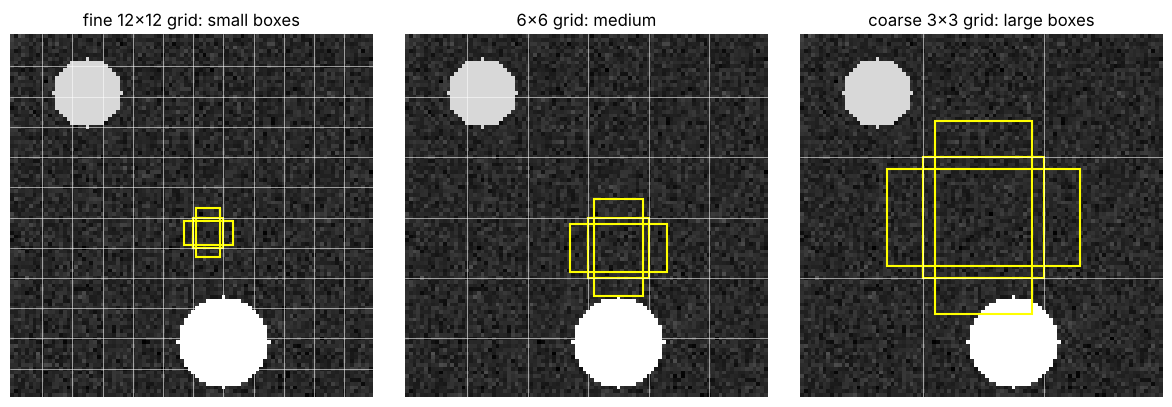

In [10]:
# The six feature maps of SSD300 (input 300x300) and how many default boxes each contributes
ssd_maps = [(38, 4), (19, 6), (10, 6), (5, 6), (3, 4), (1, 4)]   # (grid size, boxes per cell)
total = 0
print(f"{'feature map':>12} {'cell size':>10} {'boxes':>7}   detects")
for size, k in ssd_maps:
    n = size * size * k; total += n
    kind = "small objects" if size >= 19 else ("medium objects" if size >= 5 else "large objects")
    print(f"{size:>8}x{size:<3} {300 / size:>8.0f}px {n:>7}   {kind}")
print(f"{'total':>12} {'':>10} {total:>7} default boxes checked in ONE pass")

fig, ax = plt.subplots(1, 3, figsize=(12, 4))
img, b, l = test_scenes[1]
for a, (grid, title) in zip(ax, [(12, "fine 12x12 grid: small boxes"), (6, "6x6 grid: medium"), (3, "coarse 3x3 grid: large boxes")]):
    a.imshow(img, cmap="gray"); a.set_title(title); a.axis("off")
    cell = IMG / grid
    for g in range(1, grid):
        a.axhline(g * cell, color="white", lw=0.4); a.axvline(g * cell, color="white", lw=0.4)
    cx = cy = (grid // 2 + 0.5) * cell                       # draw the default boxes of one cell
    for w, h in [(cell, cell), (cell * 1.6, cell * 0.8), (cell * 0.8, cell * 1.6)]:
        a.add_patch(mpatches.Rectangle((cx - w / 2, cy - h / 2), w, h, fill=False, ec="yellow", lw=1.5))
plt.tight_layout(); plt.show()

Our TinyYOLO uses a single 6×6 grid, and each cell predicts **one** object (the one whose centre falls in it). Our random training scenes never put two centres in the same cell. But in real photos, small objects in a crowd do: a flock of birds, people far away, distant cars. Let's build such a scene by hand. A small circle and a small square are placed so that **both centres fall in the same 16×16 cell** (row 1, column 1), with a normal triangle elsewhere for comparison.

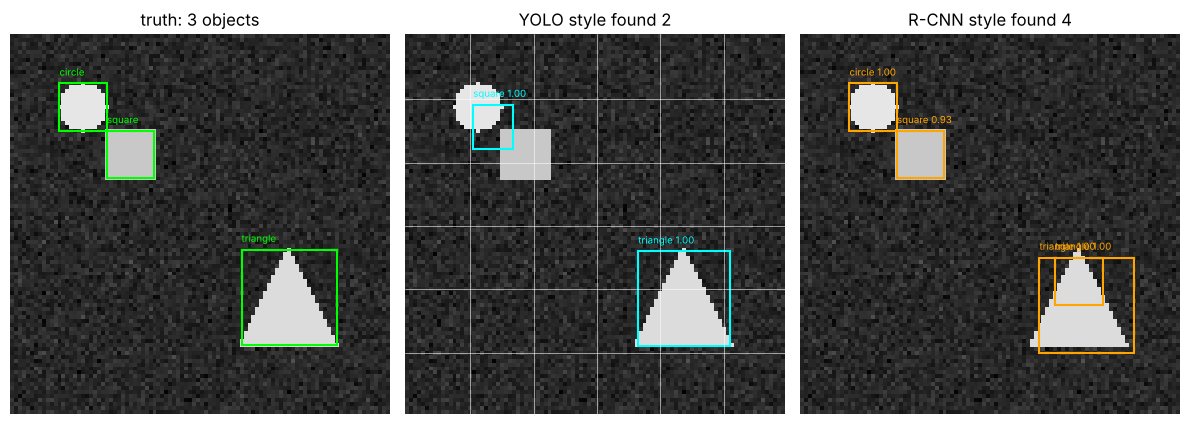

YOLO-style precision/recall on this scene  : [0.5, 0.33]
R-CNN-style precision/recall on this scene : [0.75, 1.0]


In [11]:
crowded = np.random.default_rng(5).normal(40, 12, (IMG, IMG)).clip(0, 255).astype(np.uint8)
draw_shape(crowded, 0, 18, 18, 6, 230)      # small circle, centre (18, 18) -> cell (1, 1)
draw_shape(crowded, 1, 30, 30, 6, 200)      # small square, centre (30, 30) -> ALSO cell (1, 1)
draw_shape(crowded, 2, 70, 66, 12, 220)     # a normal triangle elsewhere
crowded_boxes = np.array([[12, 12, 24, 24], [24, 24, 36, 36], [58, 54, 82, 78]], np.float32)
crowded_labels = np.array([0, 1, 2])

with torch.no_grad():
    yolo_found = yolo_decode(yolo(torch.tensor(crowded, dtype=torch.float32)[None, None] / 255)[0])
rcnn_found = rcnn_detect(crowded)

fig, ax = plt.subplots(1, 3, figsize=(12, 4.2))
show_scene(ax[0], crowded, crowded_boxes, crowded_labels); ax[0].set_title("truth: 3 objects")
show_scene(ax[1], crowded, [p[0] for p in yolo_found], [p[2] for p in yolo_found], [p[1] for p in yolo_found], color="cyan")
ax[1].set_title(f"YOLO style found {len(yolo_found)}")
show_scene(ax[2], crowded, [p[0] for p in rcnn_found], [p[2] for p in rcnn_found], [p[1] for p in rcnn_found], color="orange")
ax[2].set_title(f"R-CNN style found {len(rcnn_found)}")
for g in range(1, S):                                   # draw YOLO's grid on the middle panel
    ax[1].axhline(g * CELL, color="white", lw=0.4); ax[1].axvline(g * CELL, color="white", lw=0.4)
plt.tight_layout(); plt.show()
print("YOLO-style precision/recall on this scene  :", [round(v, 2) for v in evaluate([yolo_found], [(crowded, crowded_boxes, crowded_labels)])])
print("R-CNN-style precision/recall on this scene :", [round(v, 2) for v in evaluate([rcnn_found], [(crowded, crowded_boxes, crowded_labels)])])

**What happened:** both small shapes have their centres in the **same grid cell**, and that cell can output only one box. TinyYOLO produces a single, badly placed box somewhere between the circle and the square, and misses one object completely. The R-CNN style detector checks thousands of independent windows, so it finds **both** small shapes, at over 100× the cost. (It also leaves a duplicate box on the triangle, a reminder that its partial-window problem never fully goes away.)

This is YOLO's "**less accurate for small objects**" weakness in miniature. The original YOLO used a 7×7 grid with only 2 boxes per cell, so flocks of birds or distant crowds lost objects exactly like this.

### How would you adapt YOLO for very small objects? (Hard Q6)
- **Higher input resolution** and/or a **finer grid** (more, smaller cells).
- **Multi-scale prediction heads**, as SSD does (later YOLO versions, v3 onwards, predict at 3 scales using a Feature Pyramid Network).
- **More boxes per cell / anchors sized for small objects** (choose anchor sizes by clustering the training boxes).
- **Tiling**: cut a large image into overlapping tiles, detect in each and merge (common for drone and satellite images).
- **Data augmentation** (mosaic, copy-paste of small objects) and giving small objects more weight in the loss.

## 6 · Which architecture for which job? (Medium Q13–14)

| | Medical imaging | Autonomous driving |
|---|---|---|
| Priority | **Accuracy > speed** | **Speed > accuracy** |
| Choice | **R-CNN family** (Faster R-CNN; Mask R-CNN for exact outlines) | **YOLO** (or SSD) |
| Why | missing a tumour (a false negative) is unacceptable; small lesions need precise localization; analysis is offline, so a few seconds per scan is fine | must detect pedestrians, vehicles and signs **in real time** (30+ frames/second); a slightly less precise box *now* beats a perfect box too late |
| Example | finding small tumours in MRI scans | spotting a pedestrian stepping onto the road |

**Key insight:** the choice depends on the application's **tolerance for errors** versus its **need for real-time performance**.

## 7 · Optional: try a real pretrained detector on your own photo
Our toy models only know circles, squares and triangles. Real detectors trained on COCO know 80 classes (person, car, dog…). This cell downloads a pretrained **Faster R-CNN** (~160 MB) the first time, so set `RUN = True` on your own machine with internet.

In [12]:
RUN = False          # set to True to try it (downloads weights on first run)
IMAGE_PATH = "../../week-1/code/sample.jpg"

if RUN:
    from torchvision.models.detection import fasterrcnn_resnet50_fpn, FasterRCNN_ResNet50_FPN_Weights
    weights = FasterRCNN_ResNet50_FPN_Weights.DEFAULT
    detector = fasterrcnn_resnet50_fpn(weights=weights).eval()
    photo = cv2.cvtColor(cv2.imread(IMAGE_PATH), cv2.COLOR_BGR2RGB)
    with torch.no_grad():
        out = detector([torch.tensor(photo).permute(2, 0, 1).float() / 255])[0]
    plt.figure(figsize=(10, 6)); plt.imshow(photo); plt.axis("off")
    for box, label, score in zip(out["boxes"], out["labels"], out["scores"]):
        if score > 0.6:
            x1, y1, x2, y2 = box.tolist()
            plt.gca().add_patch(mpatches.Rectangle((x1, y1), x2 - x1, y2 - y1, fill=False, ec="red", lw=2))
            plt.text(x1, y1, f"{weights.meta['categories'][label]} {score:.2f}", color="white", backgroundcolor="red", fontsize=8)
    plt.show()
else:
    print("Skipped. Set RUN = True to download and run a pretrained Faster R-CNN on your own image.")

Skipped. Set RUN = True to download and run a pretrained Faster R-CNN on your own image.


---
## ✅ Check yourself
1. What does object detection identify? *(what each object is (class) and where it is (bounding box))*
2. What do R-CNN, YOLO and SSD stand for? *(Region-based CNN; You Only Look Once; Single Shot MultiBox Detector)*
3. Why is R-CNN slow? *(it runs a CNN separately on ~2,000 region proposals per image)*
4. How does YOLO treat detection differently? *(as one regression problem: a grid predicts boxes and classes in a single forward pass)*
5. Why is SSD good with different object sizes? *(it predicts from several feature maps: fine maps for small objects, coarse maps for large ones)*
6. What do IoU and NMS do? *(IoU measures box overlap; NMS keeps the best box and removes overlapping duplicates)*
7. Medical imaging vs self-driving: which detector and why? *(R-CNN family for accuracy; YOLO/SSD for real-time speed)*